# 00. Data Preprocessing: The Builder Pipeline

**Project:** Synthetic Raman Spectra Generation for Glioma Detection  
**Role:** Builder (Raw Data $\rightarrow$ Processed HDF5)

This notebook executes the **one-time** preprocessing pipeline required to convert the raw 2D spectral scans into a machine-learning-ready dataset. Due to the computational cost of baseline correction algorithms, we separate this "Building" phase from the "Training" phase.

### Objectives
1.  **Ingest:** Load raw `.npy` spectral cubes from the `data/raw/` directory.
2.  **Align:** Match spectra with their corresponding ground-truth tumor maps (`data/tumor_maps.npy`).
3.  **Clean:** Apply baseline correction and normalization to remove non-biological noise.
4.  **Structure:** Save the processed dataset into a highly optimized Hierarchical Data Format (HDF5) file for efficient I/O during training.

## Preprocessing Methodology

Raman spectra are inherently noisy and contain background fluorescence that must be removed before training deep learning models. This pipeline applies the following transformations:

### 1. Baseline Correction: AirPLS
We utilize **Adaptive Iteratively Reweighted Penalized Least Squares (AirPLS)**. 
* **Purpose:** Removes the sloping background fluorescence (baseline drift) that varies between samples and spectrometers, while preserving the sharp Raman peaks that correspond to molecular vibrations.
* **Parameters:** `lambda=100`, `porder=1`.

### 2. Normalization: Min-Max
* **Purpose:** Scales the intensity of each spectrum to the range `[0, 1]`.
* **Why:** Neural networks (like VAEs and CNNs) converge significantly faster and more stably when input features are normalized.

### 3. Quality Control
* **Exclusion:** The sample `HF-1887_via-t_2_1.h5_3` is explicitly excluded from the dataset (as per previous literature, see APOLLO project) due to data quality issues.
* **Clipping:** Negative values resulting from baseline subtraction are clipped to 0.

In [ ]:
# 00_Preprocessing.ipynb
# CONFIG-DRIVEN PREPROCESSING

import sys
import os
from pathlib import Path

# ============================================================================
# CRITICAL: Change to project root so relative paths resolve correctly
# ============================================================================
# When notebook runs from /notebooks, relative paths like "results/..." get
# resolved as "notebooks/results/..." which is WRONG.
# We need to be in the project root (one level up)
notebook_dir = Path.cwd()
project_root = notebook_dir.parent
os.chdir(project_root)
print(f"Changed working directory to: {os.getcwd()}")

# Add project root to path so we can import 'src'
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.config import setup_experiment
from src.data.preprocessing import RamanPreprocessor
from src.data.loader import GliomaDataLoader
import numpy as np
import matplotlib.pyplot as plt

# ============================================================================
# STEP 1: Load Configuration from exp_103.yaml
# ============================================================================
config, output_dir = setup_experiment('exp_103')

print(f"\n{'='*80}")
print(f"CONFIGURATION LOADED: {config['name']}")
print(f"{'='*80}")
print(f"Description: {config['description']}")
print(f"Output directory: {output_dir}")
print(f"\nPreprocessing Strategy:")
print(f"  Mask strategy: {config['preprocessing']['mask_strategy']}")
print(f"  Spatial median filter: {config['preprocessing']['spatial_median_filter']}")
print(f"  AirPLS lambda: {config['preprocessing']['airpls_lambda']}")
print(f"  Normalization: {config['preprocessing']['normalization']}")

print(f"\nKey paths:")
print(f"  Raw data: {config['paths']['raw_data_dir']}")
print(f"  Processed: {config['paths']['processed_file']}")
print(f"  Calib: {config['paths']['calib_file']}")
print(f"{'='*80}\n")

# ============================================================================
# STEP 2: Initialize Preprocessor with Config
# ============================================================================
preprocessor = RamanPreprocessor(
    raw_data_dir=config['paths']['raw_data_dir'],
    tumor_maps_path=config['preprocessing'].get('tumor_maps_path'),
    calibration_path=config['paths']['calib_file'],
    output_file=config['paths']['processed_file'],
    mask_strategy=config['preprocessing']['mask_strategy'],
    config=config  # Pass entire config for parameter extraction
)

print(f"Preprocessor initialized:")
print(f"  Source: {preprocessor.raw_data_dir}")
print(f"  Target: {preprocessor.output_file}")
print(f"  Strategy: {preprocessor.mask_strategy}")


Changed working directory to: c:\Users\Andrei\incdsb\New folder


KeyError: 'models_baseline_dir'

>  **IMPORTANT USAGE NOTE**
>
> **Run this notebook only ONCE.**
>
> The AirPLS algorithm is computationally intensive. Processing ~300,000 spectra may take **1-2 hours** depending on your CPU. Once the `glioma_dataset.h5` file is generated, you do not need to run this notebook again unless the raw data changes.
>
> Future experiments (CVAE, SVM, etc.) will simply load the processed `.h5` file in seconds.

Current Strategy: 'tumor_map'
Found 59 raw files. Searching for first valid tissue sample...
   Loading tumor maps from results\exp_102\tumor_maps.npy...

   SUCCESS: Found tissue in HF-448_V5B_1.h5_3.npy
   Cube Shape: (60, 60, 1738)
   Tissue Pixels: 3497


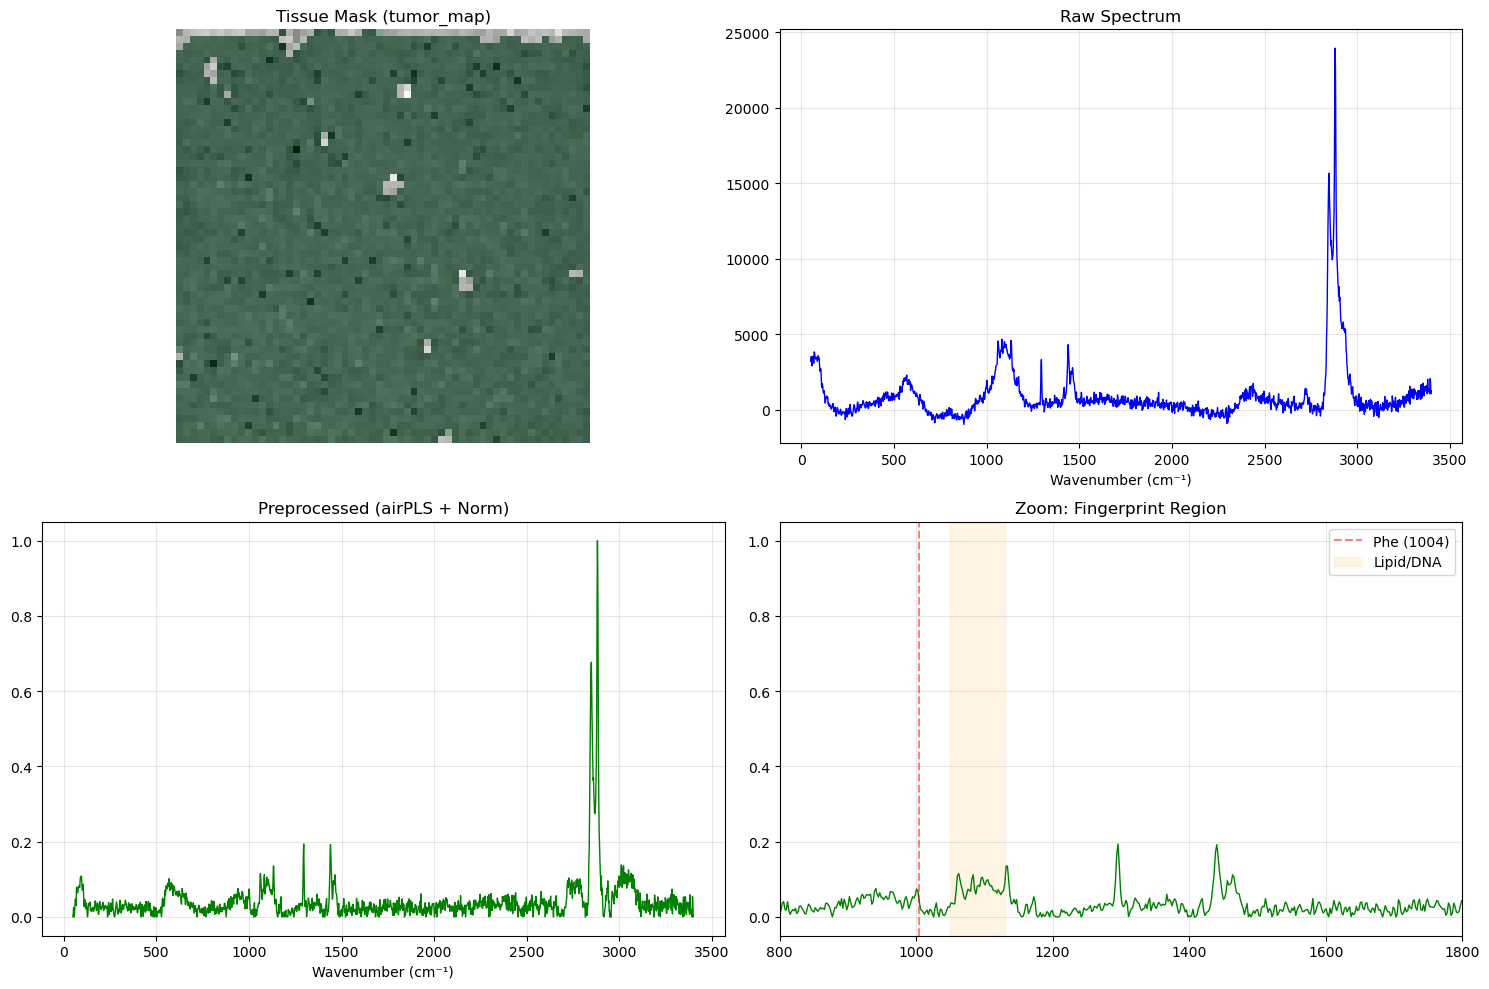

Stats:
Raw range: -983.5 - 23948.7
Proc range: 0.000 - 1.000


In [8]:
# --- Step 1.5: Visual Proof-of-Concept ---
# Test preprocessing on a single real tissue spectrum based on selected strategy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import natsort
import os
import glob
import tqdm

# 1. Get list of files
raw_files = natsort.natsorted(list(Path(preprocessor.raw_data_dir).rglob("*.npy")))

print(f"Current Strategy: '{preprocessor.mask_strategy}'")
print(f"Found {len(raw_files)} raw files. Searching for first valid tissue sample...")

# 2. Lazy Load & Check for Tissue
test_file = None
test_mask = None
raw_cube = None
tumor_maps_lookup = {}

# If strategy is tumor_map, load them once
if preprocessor.mask_strategy == "tumor_map":
    print(f"   Loading tumor maps from {preprocessor.tumor_maps_path}...")
    try:
        loaded_maps = np.load(preprocessor.tumor_maps_path, allow_pickle=True)
        if loaded_maps.ndim == 0: loaded_maps = loaded_maps.item()
        
        if isinstance(loaded_maps, dict) and 'data' in loaded_maps:
            tumor_maps_lookup = loaded_maps['data']
        elif isinstance(loaded_maps, dict):
             tumor_maps_lookup = loaded_maps
        else:
             print("Warning: Tumor map structure ambiguous. Map lookup might fail.")
    except Exception as e:
        print(f"Failed to load tumor maps: {e}")

# Search loop
for filepath in raw_files:
    # Skip excluded files
    if any(ex in str(filepath) for ex in preprocessor.IGNORE_SAMPLES):
        continue
        
    try:
        # Load raw data
        cube = np.load(str(filepath))
        filename = filepath.name
        mask = None
        
        # --- STRATEGY LOGIC ---
        if preprocessor.mask_strategy == "bio_mask":
            # Dynamic calculation using your new robust filter
            mask = preprocessor._create_bio_mask(cube)
            
        elif preprocessor.mask_strategy == "tumor_map":
            # Lookup logic
            key = filename
            if key not in tumor_maps_lookup: key = filename.replace('.npy', '')
            t_map = tumor_maps_lookup.get(key)
            if t_map is not None: mask = (t_map == 1)
        
        # Check yield
        if mask is not None and np.sum(mask) > 10: # Found a good sample!
            test_file = filepath
            test_mask = mask
            raw_cube = cube
            break
            
    except Exception as e:
        print(f"Skipping {filepath.name}: {e}")
        continue

# 3. Visualize
if test_file is None:
    print("No valid tissue found in the scanned files.")
else:
    print(f"\n   SUCCESS: Found tissue in {test_file.name}")
    print(f"   Cube Shape: {raw_cube.shape}")
    print(f"   Tissue Pixels: {np.sum(test_mask)}")
    
    # Extract
    valid_spectra = raw_cube[test_mask]
    
    # Pick random spectrum
    idx = np.random.randint(0, valid_spectra.shape[0])
    raw_spec = valid_spectra[idx]
    
    # Preprocess
    proc_spec = preprocessor._preprocess_spectrum(raw_spec)
    
    # Plot
    wavenumbers = preprocessor.wavenumbers
    
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    
    # Mask Visualization
    ax_map = axes[0, 0]
    ax_map.imshow(np.mean(raw_cube, axis=2), cmap='gray')
    ax_map.imshow(test_mask, cmap='Greens', alpha=0.5)
    ax_map.set_title(f"Tissue Mask ({preprocessor.mask_strategy})")
    ax_map.axis('off')
    
    # Raw Spectrum
    ax_raw = axes[0, 1]
    ax_raw.plot(wavenumbers, raw_spec, 'b-', lw=1)
    ax_raw.set_title("Raw Spectrum")
    ax_raw.set_xlabel("Wavenumber (cm⁻¹)")
    ax_raw.grid(True, alpha=0.3)
    
    # Processed Spectrum
    ax_proc = axes[1, 0]
    ax_proc.plot(wavenumbers, proc_spec, 'g-', lw=1)
    ax_proc.set_title("Preprocessed (airPLS + Norm)")
    ax_proc.set_xlabel("Wavenumber (cm⁻¹)")
    ax_proc.grid(True, alpha=0.3)
    
    # Zoom in on Bio-Markers
    ax_zoom = axes[1, 1]
    ax_zoom.plot(wavenumbers, proc_spec, 'g-', lw=1)
    ax_zoom.set_title("Zoom: Fingerprint Region")
    ax_zoom.set_xlim(800, 1800) # Most relevant region
    ax_zoom.grid(True, alpha=0.3)
    
    # Highlight Key Markers
    ax_zoom.axvline(1004, color='r', linestyle='--', alpha=0.5, label='Phe (1004)')
    ax_zoom.axvspan(1050, 1130, color='orange', alpha=0.1, label='Lipid/DNA')
    ax_zoom.legend()
    
    plt.tight_layout()
    plt.show()
    
    print("Stats:")
    print(f"Raw range: {raw_spec.min():.1f} - {raw_spec.max():.1f}")
    print(f"Proc range: {proc_spec.min():.3f} - {proc_spec.max():.3f}")

In [ ]:
# Generate RGB images for all scans using the configured strategy (for visual QC)

import natsort
import tqdm

# Use paths from config
RAW_DATA_DIR = Path(config['paths']['raw_data_dir'])
OUTPUT_IMG_DIR = Path(config['paths']['quality_dir']) / 'rgb_images'

# Create output directory
os.makedirs(OUTPUT_IMG_DIR, exist_ok=True)
print(f"Output folder created: {OUTPUT_IMG_DIR}")

# Load calibration via preprocessor
wavenumbers = preprocessor.wavenumbers

# --- 1. Visualize Bio-Markers as False Color RGB ---
def raman_to_bio_rgb(hsi_cube, wavenumbers):
    """
    Converts a Raman Hyperspectral Cube to a 'False Color' RGB image 
    highlighting biological markers.
    
    Args:
        hsi_cube: (H, W, D) Raw or Preprocessed Data
        wavenumbers: (D,) Vector of cm^-1 values
    
    Returns:
        rgb_img: (H, W, 3) Normalized image for display
    """
    H, W, D = hsi_cube.shape
    
    # --- 1. Define Marker Indices ---
    # RED Channel: Phenylalanine (1004 cm^-1) - The "Sharp" Marker
    idx_phe_start = np.argmin(np.abs(wavenumbers - 990))
    idx_phe_end   = np.argmin(np.abs(wavenumbers - 1020))
    
    # GREEN Channel: C-H Stretch (2850-2950 cm^-1) - The "Massive" Marker (Lipids)
    idx_hwn_start = np.argmin(np.abs(wavenumbers - 2800))
    idx_hwn_end   = np.argmin(np.abs(wavenumbers - 3000))
    
    # BLUE Channel: CH2 Deformation (1440-1450 cm^-1) - General Organic
    idx_ch2_start = np.argmin(np.abs(wavenumbers - 1430))
    idx_ch2_end   = np.argmin(np.abs(wavenumbers - 1460))
    
    # --- 2. Extract Bands (Integration/Sum) ---
    R = np.sum(hsi_cube[:, :, idx_phe_start:idx_phe_end], axis=2)
    G = np.sum(hsi_cube[:, :, idx_hwn_start:idx_hwn_end], axis=2)
    B = np.sum(hsi_cube[:, :, idx_ch2_start:idx_ch2_end], axis=2)
    
    # --- 3. Normalize per Channel (Contrast Stretch) ---
    def norm(c):
        c = c - np.min(c)
        return c / (np.max(c) + 1e-8)
    
    R = norm(R)
    G = norm(G)
    B = norm(B)
    
    # --- 4. Stack ---
    rgb_img = np.stack([R, G, B], axis=-1)
    rgb_img = np.power(rgb_img, 0.8)  # Boost gamma for visibility
    
    return rgb_img

# --- 2. Processing Loop ---
raw_files = natsort.natsorted(list(RAW_DATA_DIR.rglob("*.npy")))
print(f"Found {len(raw_files)} scans. Generating images...")

for filepath in tqdm.tqdm(raw_files, desc="Saving Images"):
    filename = filepath.name
    if "via-t" in filename: 
        continue

    try:
        raw_cube = np.load(filepath)
        if isinstance(raw_cube, np.ndarray) and raw_cube.dtype == 'O':
             raw_cube = raw_cube.item().get('data', raw_cube)
        
        rgb_img = raman_to_bio_rgb(raw_cube, wavenumbers)
        
        save_name = filename.replace('.npy', '.png')
        plt.imsave(OUTPUT_IMG_DIR / save_name, rgb_img)
        
    except Exception as e:
        print(f"Failed {filename}: {e}")

print(f"All images saved to {OUTPUT_IMG_DIR}")


Output folder created: ..\data\rgb_img_bio_markers
Calibration loaded. Shape: (1738,)
Found 59 scans. Generating images...


AttributeError: type object 'tqdm' has no attribute 'tqdm'

In [9]:
# --- Pre-Calculation / Dry Run ---
# Census: count how many spectra we'll extract from each file

import numpy as np
import os
from tqdm import tqdm

# Use configured strategy from config
STRATEGY = config['preprocessing']['mask_strategy']
print(f"Starting Census using strategy: '{STRATEGY}'...")
print(f"Configuration from: exp_102.yaml\n")

# Initialize preprocessor already initialized above - use it for mask logic
RAW_DATA_DIR = Path(config['paths']['raw_data_dir'])

# Find files
raw_files = sorted([p for p in RAW_DATA_DIR.glob("LGm-*/*.npy")])
total_spectra = 0
files_with_tissue = 0

print(f"Scanning {len(raw_files)} raw files...")

for filepath in tqdm(raw_files, desc="Census"):
    filepath = Path(filepath)
    filename = filepath.name

    # Skip ignored files from config
    if any(ignored in filename for ignored in preprocessor.IGNORE_SAMPLES):
        continue

    try:
        raw_cube = np.load(str(filepath))
        if isinstance(raw_cube, np.ndarray) and raw_cube.dtype == 'O':
            raw_cube = raw_cube.item().get('data', raw_cube)

        # Calculate Mask using configured strategy
        if STRATEGY == "tumor_map":
            # Load tumor maps (if configured)
            mask = None
            if preprocessor.tumor_maps_path and preprocessor.tumor_maps_path.exists():
                tumor_maps = np.load(preprocessor.tumor_maps_path, allow_pickle=True).item()
                if filename in tumor_maps:
                    mask = (tumor_maps[filename] == 1)
        else:
            # Use bio_mask strategy (physics-based)
            mask = preprocessor._create_bio_mask(raw_cube)
        
        n_tissue = np.sum(mask) if mask is not None else 0

        if n_tissue > 0:
            total_spectra += n_tissue
            files_with_tissue += 1

    except Exception as e:
        print(f"Error reading {filename}: {e}")
        continue

print("-" * 30)
print(f"   Census Complete ({STRATEGY})")
print(f"   Files containing tissue: {files_with_tissue} / {len(raw_files)}")
print(f"   Total Expected Spectra: {total_spectra}")
print("-" * 30)


Starting Census using strategy: 'tumor_map'...
Configuration from: exp_102.yaml

Scanning 59 raw files...


Census: 100%|██████████| 59/59 [00:00<00:00, 88.66it/s]

------------------------------
   Census Complete (tumor_map)
   Files containing tissue: 58 / 59
   Total Expected Spectra: 226284
------------------------------


In [11]:
# --- Bias Check ---
# Check which classes the rejected files belong to and analyze distribution

import re

rejected_classes = {i: 0 for i in range(1, 7)}
accepted_classes = {i: 0 for i in range(1, 7)}
rejected_files = []

STRATEGY = config['preprocessing']['mask_strategy']  # Use configured strategy
RAW_DATA_DIR = Path(config['paths']['raw_data_dir'])

print("Rejected Files Analysis:")

raw_files = sorted([p for p in RAW_DATA_DIR.glob("LGm-*/*.npy")])

for filepath in raw_files:
    filename = os.path.basename(filepath)
    
    # Skip explicitly ignored files
    if any(ignored in filename for ignored in preprocessor.IGNORE_SAMPLES):
        continue
    
    # Extract class from path (LGm-X)
    class_dir = None
    p = Path(filepath)
    for part in p.parts:
        if part.lower().startswith('lgm-'):
            try:
                class_dir = int(part.split('-', 1)[1])
            except Exception:
                class_dir = None
            break

    # Fallback: try to infer from filename
    if class_dir is None:
        m = re.search(r'LGm[-_ ]?(\d)', str(p), re.IGNORECASE)
        if m:
            class_dir = int(m.group(1))
        else:
            continue
    
    try:
        raw_cube = np.load(str(filepath))
        if isinstance(raw_cube, np.ndarray) and raw_cube.dtype == 'O':
            raw_cube = raw_cube.item().get('data', raw_cube)
        
        # Calculate mask using configured strategy
        mask = None
        if STRATEGY == "tumor_map":
            if preprocessor.tumor_maps_path and preprocessor.tumor_maps_path.exists():
                tumor_maps = np.load(preprocessor.tumor_maps_path, allow_pickle=True).item()
                if filename in tumor_maps:
                    mask = (tumor_maps[filename] == 1)
        else:
            mask = preprocessor._create_bio_mask(raw_cube)
        
        n_tissue = np.sum(mask) if mask is not None else 0
        
        if n_tissue > 0:
            accepted_classes[class_dir] += n_tissue
        else:
            rejected_classes[class_dir] += 1
            rejected_files.append((filename, class_dir))
    
    except Exception as e:
        rejected_classes[class_dir] += 1
        rejected_files.append((filename, class_dir, str(e)))

# Print Analysis
print(f"\nClass Distribution Analysis (using {STRATEGY}):")
print(f"{'Class':<10} {'Accepted Spectra':<20} {'Rejected Files':<20}")
print("-" * 50)

total_by_class = 0
for class_num in range(1, 7):
    accepted = accepted_classes[class_num]
    rejected = rejected_classes[class_num]
    total_by_class += accepted
    print(f"LGm-{class_num:<3} {accepted:<20} {rejected:<20}")

print("-" * 50)
print(f"Accepted Spectra Count: {total_spectra}")
print(f"   (Sum across classes: {total_by_class})")
print(f"   Total Rejected Files: {sum(rejected_classes.values())}")

if rejected_files:
    print(f"\nSample of Rejected Files:")
    for item in rejected_files[:10]:
        if len(item) == 3:
            print(f"   {item[0]} (LGm-{item[1]}): {item[2]}")
        else:
            print(f"   {item[0]} (LGm-{item[1]})")
    if len(rejected_files) > 10:
        print(f"   ... and {len(rejected_files) - 10} more")


Rejected Files Analysis:

Class Distribution Analysis (using tumor_map):
Class      Accepted Spectra     Rejected Files      
--------------------------------------------------
LGm-1   16024                0                   
LGm-2   52032                0                   
LGm-3   45710                0                   
LGm-4   44005                0                   
LGm-5   55045                0                   
LGm-6   13468                0                   
--------------------------------------------------
Accepted Spectra Count: 226284
   (Sum across classes: 226284)
   Total Rejected Files: 0


In [12]:
# --- Step 2: Run the Pipeline ---
# This will take time (approx 1-2 hours for 300k spectra due to airPLS)
# The progress bar will show the status.
preprocessor.run()

Found 59 scan files.
Loading Tumor Maps from results\exp_102\tumor_maps.npy...
Legacy Mode: Output shape is 1738 features (Full spectrum, no cropping).


Processing:   0%|          | 0/59 [00:00<?, ?it/s]

Applying spatial median filter (size=3×3)...


Processing:   2%|▏         | 1/59 [00:48<46:51, 48.48s/it]

Applying spatial median filter (size=3×3)...


Processing:   3%|▎         | 2/59 [01:49<52:50, 55.62s/it]

... (110 outputs left out)

Applying spatial median filter (size=3×3)...


Processing: 100%|██████████| 59/59 [44:42<00:00, 45.46s/it]



Processing complete. Saved to c:\Users\Andrei\incdsb\New folder\glioma-synthetic-data\results\exp_102\data\glioma_dataset.h5

QUALITY FILTER STATISTICS:
  Total spectra processed:  226,284
  Passed quality checks:    226,284 (100.0%)
  Rejected as junk:         0 (0.0%)


RuntimeError: Unable to synchronously get dataspace (identifier is not of specified type)

In [13]:
# Verify output file
import h5py
with h5py.File('results/exp_102/data/glioma_dataset.h5', 'r') as f:
    print(f"Spectra: {f['spectra'].shape}")
    print(f"Keys: {list(f.keys())}")

Spectra: (226284, 1738)
Keys: ['coords', 'patient_ids', 'sample_ids', 'spectra', 'spectra_smoothed', 'wavenumbers', 'y_class', 'y_tumor']


📂 Loading data from ../data/processed/glioma_dataset.h5...
✅ Loaded 277764 Total Spectra (Tumor + Healthy).
🔄 Running PCA...


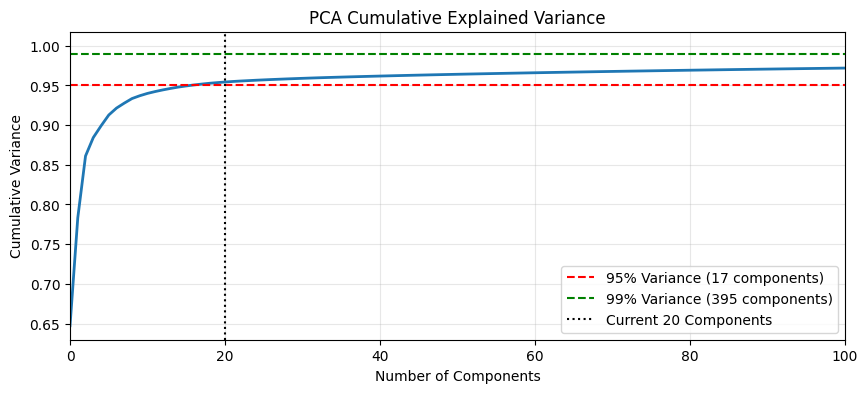

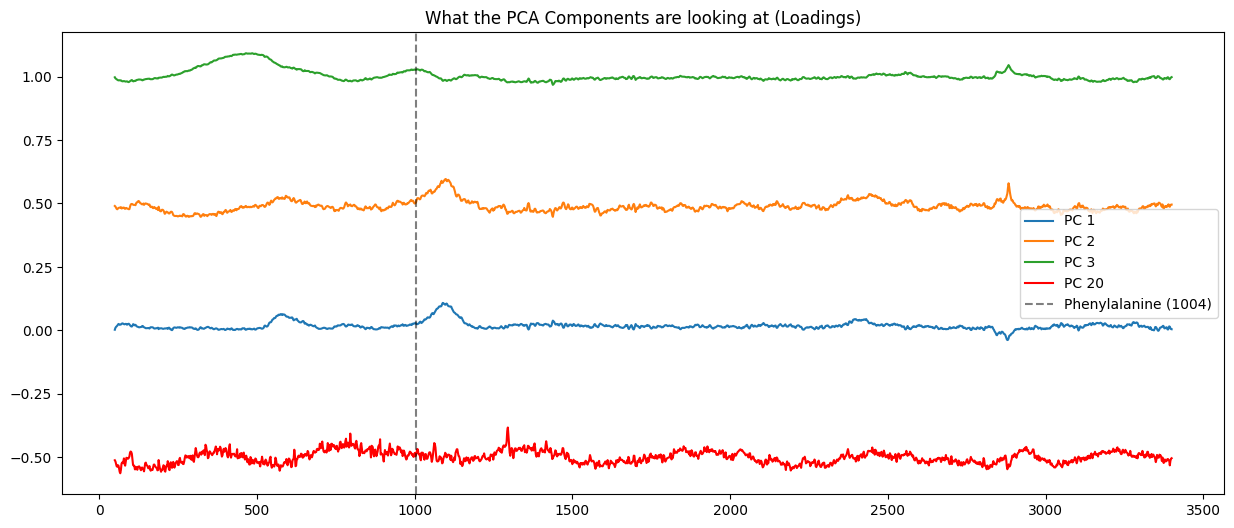

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Use config path
loader = GliomaDataLoader(config['paths']['processed_file'], memory_mapped=True)
X_sample = loader.X[:20000] # Subsample for speed

print("Running PCA...")
pca = PCA().fit(X_sample)

# 1. Explained Variance (Scree Plot)
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
target_95 = np.argmax(cumulative_variance >= 0.95) + 1
target_99 = np.argmax(cumulative_variance >= 0.99) + 1

plt.figure(figsize=(10, 4))
plt.plot(cumulative_variance, linewidth=2)
plt.axhline(0.95, color='r', linestyle='--', label=f'95% Variance ({target_95} components)')
plt.axhline(0.99, color='g', linestyle='--', label=f'99% Variance ({target_99} components)')
plt.axvline(20, color='k', linestyle=':', label='Current 20 Components')
plt.title("PCA Cumulative Explained Variance")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Variance")
plt.xlim(0, 100)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 2. Inspect the "Loadings" to ensure we aren't throwing away peaks
plt.figure(figsize=(15, 6))
for i in range(3):
    plt.plot(loader.wavenumbers, pca.components_[i] + (i * 0.5), label=f'PC {i+1}')
    
plt.plot(loader.wavenumbers, pca.components_[19] - 0.5, color='red', label='PC 20')

plt.title("What the PCA Components are looking at (Loadings)")
plt.axvline(1004, color='black', linestyle='--', alpha=0.5, label='Phenylalanine (1004)')
plt.legend()
plt.show()


In [ ]:
import h5py
import numpy as np
import joblib
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from pathlib import Path
import os

# Use config paths
DATA_PATH = config['paths']['processed_file']
MODEL_DIR = Path(config['paths']['quality_dir']) / 'models'
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Starting Phase 1: Global GMM Annotation...")
print(f"Data path: {DATA_PATH}\n")

# 1. Open HDF5 in Read/Write mode ('r+')
with h5py.File(DATA_PATH, 'r+') as f:
    print(f"Loaded dataset. Found {f['spectra'].shape[0]} spectra.")
    X = f['spectra'][:]
    wn = f['wavenumbers'][:]
    
    # 2. Fit PCA on ALL data
    print("   Fitting PCA (n_components=20)...")
    pca = PCA(n_components=20, random_state=42)
    X_pca = pca.fit_transform(X)
    
    # Save PCA for clinical inference step
    pca_path = MODEL_DIR / "pca_transformer.joblib"
    joblib.dump(pca, pca_path)
    print(f"   Saved PCA transformer to {pca_path}")
    
    # 3. Fit GMM
    print("   Fitting Gaussian Mixture Model (2 States)...")
    gmm = GaussianMixture(n_components=2, covariance_type='full', random_state=42)
    hidden_states = gmm.fit_predict(X_pca)
    
    # Save GMM
    gmm_path = MODEL_DIR / "gmm_annotator.joblib"
    joblib.dump(gmm, gmm_path)
    
    # 4. Identify which cluster is the Tumor
    idx_1004 = np.argmin(np.abs(wn - 1004))
    mean_state_0 = np.mean(X[hidden_states == 0, idx_1004])
    mean_state_1 = np.mean(X[hidden_states == 1, idx_1004])
    
    if mean_state_1 > mean_state_0:
        print(f"   State 1 has higher signal (Tumor). State 0 is Healthy.")
        y_tumor = hidden_states
    else:
        print(f"   State 0 has higher signal (Tumor). State 1 is Healthy.")
        y_tumor = 1 - hidden_states
        
    tumor_count = np.sum(y_tumor == 1)
    healthy_count = np.sum(y_tumor == 0)
    print(f"   Results: {tumor_count} Tumor spectra, {healthy_count} Healthy spectra.")
    
    # 5. Save to HDF5
    print("   Writing 'y_tumor' labels directly to HDF5...")
    if 'y_tumor' in f:
        print("      'y_tumor' already exists. Overwriting...")
        del f['y_tumor']
        
    f.create_dataset("y_tumor", data=y_tumor, dtype='int32')
    print("GMM Annotation Complete! Dataset is now clinically labeled.")


🚀 Starting Phase 1: Global GMM Annotation...
📂 Loaded dataset. Found 267277 spectra.
   🔄 Fitting PCA (n_components=20)...
   💾 Saved PCA transformer to ../models/clinical_pipeline/pca_transformer.joblib
   🎭 Fitting Gaussian Mixture Model (2 States)...
   🔬 State 1 has higher signal (Tumor). State 0 is Healthy.
   📊 Results: 38087 Tumor spectra, 229190 Healthy spectra.
   💾 Writing 'y_tumor' labels directly to HDF5...
✅ GMM Annotation Complete! Dataset is now clinically labeled.


## Output Data Structure

The pipeline generates a single file: `data/processed/glioma_dataset.h5`. This file acts as a structured database containing:

| Dataset Key | Shape | Dtype | Description |
| :--- | :--- | :--- | :--- |
| **`/spectra`** | `(N, Bands)` | `float32` | The cleaned, normalized 1D Raman spectra. |
| **`/y_class`** | `(N,)` | `int32` | The specific glioma sub-type (Classes 1-6). |
| **`/y_tumor`** | `(N,)` | `int32` | Binary label: `0` = Normal Tissue, `1` = Tumor. |
| **`/sample_ids`** | `(N,)` | `string` | **CRITICAL:** The unique ID of the tissue slice (e.g., `HF-448`). Used to ensure strict Train/Test separation. |
| **`/patient_ids`**| `(N,)` | `int32` | The ID of the patient. |

This structure supports **"Group-Aware Splitting"**: when we train models later, we can split data based on `/sample_ids` to ensure that pixels from the same tissue slice never leak between Training and Testing sets.

📂 Loading data from ../data/processed/glioma_dataset.h5...
✅ Data Loaded: (267277, 1738) spectra.
Total Spectra: 267277
Total Bands: 1738
Unique Samples: 58


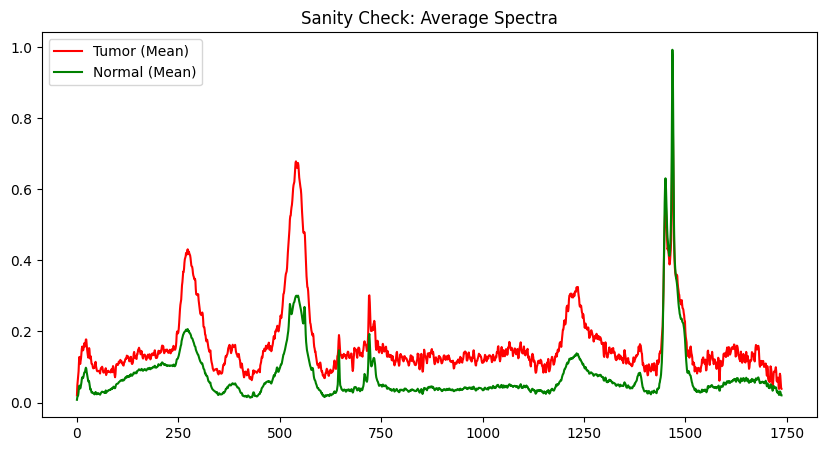

In [ ]:
# --- Step 3: Verify the Output (Sanity Check) ---
# Load the file we just created to ensure it's readable

# Use config path
loader = GliomaDataLoader(config['paths']['processed_file'], memory_mapped=True)

print(f"Total Spectra: {loader.X.shape[0]}")
print(f"Total Bands: {loader.X.shape[1]}")
print(f"Unique Samples: {len(np.unique(loader.groups))}")

# Visual Sanity Check
# Plot mean spectrum of Tumor vs Non-Tumor to see if biology is preserved
plt.figure(figsize=(10, 5))

# Indices for tumor vs normal
idx_tumor = np.where(loader.y_tumor[:] == 1)[0]
idx_normal = np.where(loader.y_tumor[:] == 0)[0]

# Compute mean (using a subset to save RAM if needed)
mean_tumor = np.mean(loader.X[idx_tumor[:5000]], axis=0)
mean_normal = np.mean(loader.X[idx_normal[:5000]], axis=0)

plt.plot(mean_tumor, color='red', label='Tumor (Mean)')
plt.plot(mean_normal, color='green', label='Normal (Mean)')
plt.title("Sanity Check: Average Spectra")
plt.legend()
plt.show()


In [ ]:
from src.data.splitter import Splitter

# --- Create Data Splits ---
# Generate and save stratified splits using config paths

splitter = Splitter(
    data_path=config['paths']['processed_file'],
    output_dir=Path(config['paths']['data_output_dir']) / 'splits'
)
splitter.generate_manual_split()

print(f" Data splits created and saved")


Saved manual splits to ../data/splits/manual_splits.json


In [ ]:
from src.data.annotator import ClinicalAnnotator

# You can swap 'gmm' to 'hdbscan' here to compare results
annotator = ClinicalAnnotator(
    data_path=config['paths']['processed_file'],
    algorithm="gmm",
    pca_variance=0.99,     # Keeps 99% of biological variance
    spatial_weight=2.0     # Forces clusters to respect (X, Y) layout
)

# Run the pipeline
annotator.annotate()


🚀 Starting Spatio-Spectral Annotation (Algorithm: GMM)...
📂 Found 58 unique slides to process.


Clustering Slides: 100%|██████████| 58/58 [15:23<00:00, 15.93s/it]


💾 Writing 'y_tumor' labels directly to HDF5...
✅ Annotation Complete!
📊 Final Dataset: 88487 Tumor spectra (31.9%) out of 277764 total tissue spectra.



🔬 Generating Visual Inspection Maps...


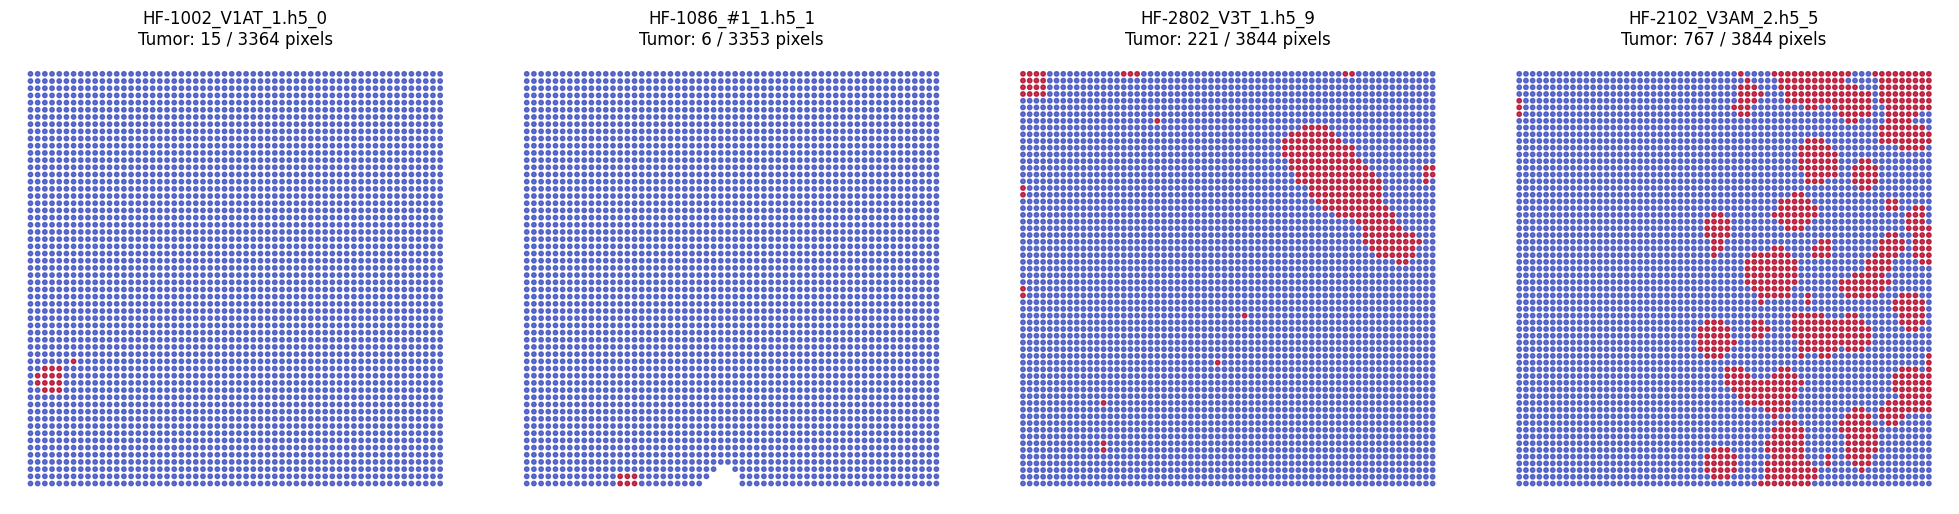

In [ ]:
import h5py

# --- 2. Visual Inspection ---
print("\n Generating Visual Inspection Maps...")

# Use config path
with h5py.File(config['paths']['processed_file'], "r") as f:
    coords = f['coords'][:]
    y_tumor = f['y_tumor'][:]
    
    raw_samples = f['sample_ids'][:]
    if isinstance(raw_samples[0], (bytes, np.bytes_)):
        samples = np.char.decode(raw_samples.astype('S'), 'utf-8')
    else:
        samples = raw_samples.astype(str)

    unique_samples = np.unique(samples)
    
    # Pick 4 random slides to inspect
    np.random.seed(42) 
    test_slides = np.random.choice(unique_samples, min(4, len(unique_samples)), replace=False)
    
    fig, axes = plt.subplots(1, len(test_slides), figsize=(5*len(test_slides), 5))
    if len(test_slides) == 1:
        axes = [axes]
    
    for ax, slide in zip(axes, test_slides):
        mask = (samples == slide)
        c_slide = coords[mask]
        l_slide = y_tumor[mask]
        
        scatter = ax.scatter(c_slide[:, 0], c_slide[:, 1], c=l_slide, cmap='coolwarm', s=10, alpha=0.8)
        ax.invert_yaxis()
        ax.set_aspect('equal')
        ax.set_title(f"{slide}\nTumor: {np.sum(l_slide)} / {len(l_slide)} pixels")
        ax.axis('off')

    plt.tight_layout()
    plt.show()

print(" Visual inspection complete")
